## Model 3: DBQA results for $^{167}$Er$^{3+}$:Y$_2$SiO$_5$ (site 2) over a field sweep

This notebook loads `simulation_results/Er_YSO_DBQA_L_8.pickle`, written by `Example_9_DBQA_Er_YSO_generate_data.ipynb`, and analyses:
1. stage A, the isolation of the 16 hyperfine states of Z1 inside the 8-qubit Hamiltonian, from cold, warm and replayed starts;
2. how the isolation threshold limits the accuracy of the Z1 transition frequencies;
3. stage B, the resolution of the hyperfine levels, and the location of the ZEFOZ point from the DBQA estimates;
4. the cost of compiling $H(\vec B)$ into a circuit, against Models 1 and 2.

In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"

import pickle

import numpy as np
import matplotlib.pyplot as plt

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))
os.makedirs("pdfs_figures", exist_ok=True)

with open("simulation_results/Er_YSO_DBQA_L_8.pickle", "rb") as file:
    data = pickle.load(file)
sweep, exact, thresholds = data["sweep"], data["exact"], data["thresholds"]
magnitudes = sweep["magnitudes"] * 1e3  # mT
i, j = sweep["transition"]
b_star = np.linalg.norm(sweep["field"]) * 1e3
print(f"sweep through the ZEFOZ point of |{i}>-|{j}> at |B*| = {b_star:.1f} mT, {len(magnitudes)} field points")

sweep through the ZEFOZ point of |6>-|7> at |B*| = 149.9 mT, 21 field points


#### Stage A: isolating Z1

Iterations of group-commutator DBQA until the 16 lowest diagonal entries span Z1 to $1-F<\epsilon$, at every field point. For the warm start and the replay the first field point is a cold start.

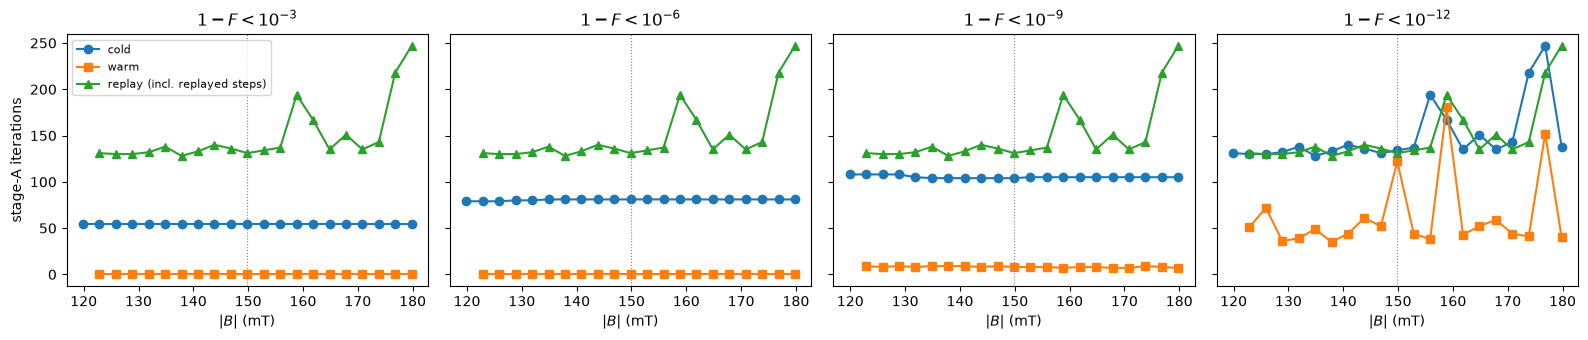

threshold           cold           warm                 replay   (mean over field points 2..N; replay: new + replayed steps)
    1e-03     54.0 (0 fail)      0.0 (0 fail)     0.0 + 149.5 (0 fail)
    1e-06     80.7 (0 fail)      0.0 (0 fail)     0.0 + 149.5 (0 fail)
    1e-09    105.2 (0 fail)      8.2 (0 fail)     0.0 + 149.5 (0 fail)
    1e-12    149.8 (0 fail)     62.8 (0 fail)     0.0 + 149.5 (0 fail)


In [2]:
def iterations(results, threshold):
    return np.array([np.nan if r is None or threshold not in r["captured"] else r["captured"][threshold]["iteration"] for r in results], float)


fig, axes = plt.subplots(1, len(thresholds), figsize=(4 * len(thresholds), 3.5), sharey=True)
for ax, threshold in zip(axes, thresholds):
    ax.plot(magnitudes, iterations(data["cold"], threshold), "o-", label="cold")
    ax.plot(magnitudes, iterations(data["warm"], threshold), "s-", label="warm")
    replay = iterations(data["replayed"], threshold) + np.array([0 if r is None else r["replayed_steps"] for r in data["replayed"]])
    ax.plot(magnitudes, replay, "^-", label="replay (incl. replayed steps)")
    ax.axvline(b_star, color="gray", lw=0.8, ls=":")
    ax.set_title(rf"$1-F < 10^{{{int(np.log10(threshold))}}}$")
    ax.set_xlabel(r"$|B|$ (mT)")
axes[0].set_ylabel("stage-A iterations")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("pdfs_figures/Er_YSO_stage_A_iterations.pdf")
plt.show()

print(f"{'threshold':>9s} {'cold':>14s} {'warm':>14s} {'replay':>22s}   (mean over field points 2..N; replay: new + replayed steps)")
for threshold in thresholds:
    c, w = iterations(data["cold"], threshold)[1:], iterations(data["warm"], threshold)[1:]
    r = iterations(data["replayed"], threshold)[1:]
    replayed = np.array([x["replayed_steps"] for x in data["replayed"][1:]])
    print(f"{threshold:9.0e} {np.nanmean(c):8.1f} ({np.sum(np.isnan(c))} fail) {np.nanmean(w):8.1f} ({np.sum(np.isnan(w))} fail) {np.nanmean(r):7.1f} + {np.mean(replayed):5.1f} ({np.sum(np.isnan(r))} fail)")

#### Isolation threshold and transition-frequency accuracy

Even if stage B diagonalised the captured block exactly, the Z1 transition frequencies would carry the restriction error of stage A, i.e. the residual coupling of the block to the other 240 states. Below: the largest error of the 120 Z1 transition frequencies when the captured block is diagonalised exactly.

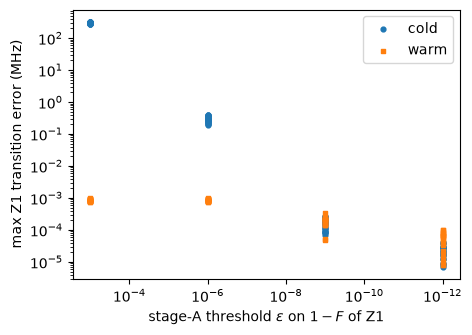

1-F < 1e-03: max Z1 transition error from the exact block spectrum: median 3.0e+02 MHz, max 3.2e+02 MHz
1-F < 1e-06: max Z1 transition error from the exact block spectrum: median 2.8e-01 MHz, max 4.1e-01 MHz
1-F < 1e-09: max Z1 transition error from the exact block spectrum: median 1.5e-04 MHz, max 2.8e-04 MHz
1-F < 1e-12: max Z1 transition error from the exact block spectrum: median 2.0e-05 MHz, max 4.2e-05 MHz


In [3]:
plt.figure(figsize=(5, 3.5))
for label, results, marker in [("cold", data["cold"], "o"), ("warm", data["warm"], "s")]:
    for k, threshold in enumerate(thresholds):
        errors = [r["captured"][threshold]["transition_error"] for r in results if r is not None and threshold in r["captured"]]
        plt.scatter([threshold] * len(errors), errors, marker=marker, color=f"C{0 if label == 'cold' else 1}", s=12, label=label if k == 0 else None)
plt.xscale("log"); plt.yscale("log")
plt.xlabel(r"stage-A threshold $\epsilon$ on $1-F$ of Z1"); plt.ylabel("max Z1 transition error (MHz)")
plt.legend(); plt.gca().invert_xaxis()
plt.savefig("pdfs_figures/Er_YSO_restriction_error.pdf", bbox_inches="tight")
plt.show()
for threshold in thresholds:
    errors = [r["captured"][threshold]["transition_error"] for r in data["cold"] if threshold in r["captured"]]
    print(f"1-F < {threshold:.0e}: max Z1 transition error from the exact block spectrum: median {np.median(errors):.1e} MHz, max {np.max(errors):.1e} MHz")

#### Stage B: resolving the hyperfine levels

Largest error of the 120 transition frequencies of Z1 from the DBQA diagonal, against the stage-B iteration, at the field point closest to $|\vec B^*|$.

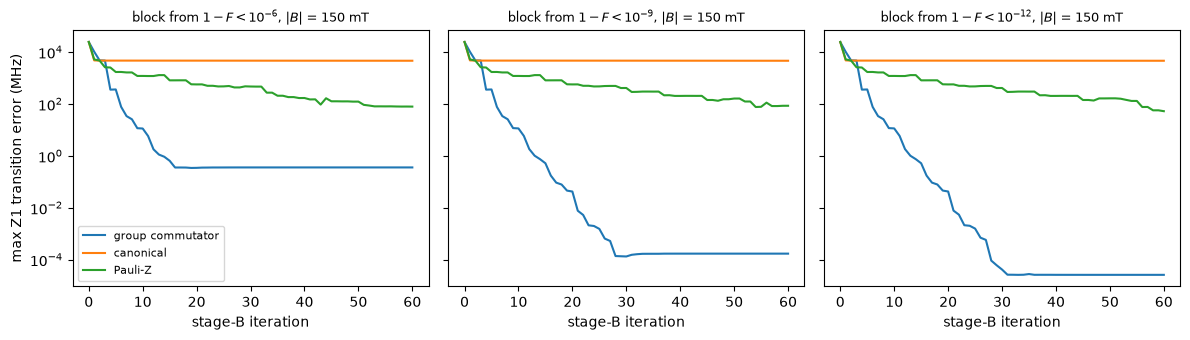

1-F < 1e-06, group commutator: error after 20 iterations 3.5e-01 MHz, final 3.6e-01 MHz; first below 0.01 MHz at -
1-F < 1e-06, canonical       : error after 20 iterations 4.7e+03 MHz, final 4.6e+03 MHz; first below 0.01 MHz at -
1-F < 1e-06, Pauli-Z         : error after 20 iterations 5.7e+02 MHz, final 7.9e+01 MHz; first below 0.01 MHz at -
1-F < 1e-09, group commutator: error after 20 iterations 4.2e-02 MHz, final 1.7e-04 MHz; first below 0.01 MHz at 21
1-F < 1e-09, canonical       : error after 20 iterations 4.7e+03 MHz, final 4.6e+03 MHz; first below 0.01 MHz at -
1-F < 1e-09, Pauli-Z         : error after 20 iterations 5.7e+02 MHz, final 8.5e+01 MHz; first below 0.01 MHz at -
1-F < 1e-12, group commutator: error after 20 iterations 4.2e-02 MHz, final 2.6e-05 MHz; first below 0.01 MHz at 21
1-F < 1e-12, canonical       : error after 20 iterations 4.7e+03 MHz, final 4.6e+03 MHz; first below 0.01 MHz at -
1-F < 1e-12, Pauli-Z         : error after 20 iterations 5.7e+02 MHz, final 5.

In [4]:
k_mid = int(np.argmin(np.abs(magnitudes - b_star)))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, threshold in zip(axes, (1e-6, 1e-9, 1e-12)):
    runs = data["stage2"][k_mid].get(threshold, {})
    for method, run in runs.items():
        ax.plot(run["transition_error"], label=method)
    ax.set_yscale("log"); ax.set_xlabel("stage-B iteration")
    ax.set_title(rf"block from $1-F < 10^{{{int(np.log10(threshold))}}}$, $|B|$ = {magnitudes[k_mid]:.0f} mT", fontsize=9)
axes[0].set_ylabel("max Z1 transition error (MHz)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("pdfs_figures/Er_YSO_stage_B.pdf")
plt.show()
for threshold in (1e-6, 1e-9, 1e-12):
    for method, run in data["stage2"][k_mid].get(threshold, {}).items():
        reached = np.nonzero(run["transition_error"] < 1e-2)[0]
        print(f"1-F < {threshold:.0e}, {method:16s}: error after 20 iterations {run['transition_error'][20]:.1e} MHz, final {run['transition_error'][-1]:.1e} MHz; "
              f"first below 0.01 MHz at {reached[0] if len(reached) else '-'}")

#### Locating the ZEFOZ point from DBQA

Along the sweep, $\nu_{ij}(b)$ has a turning point at $b = |\vec B^*|$. We fit a parabola to the DBQA estimates of $\nu_{ij}$ (group commutator, final stage-B iterate) and compare its vertex with the exact one, for each stage-A threshold.

exact: parabola vertex 152.21 mT (Newton: 149.86 mT), curvature along the line 1.48e-04 MHz/mT^2, nu varies by 0.083 MHz over the sweep
DBQA, stage A to 1-F < 1e-06: max error of nu_ij 1.2e-02 MHz, vertex 152.39 mT (error +0.18 mT)
DBQA, stage A to 1-F < 1e-09: max error of nu_ij 1.6e-05 MHz, vertex 152.20 mT (error -0.00 mT)
DBQA, stage A to 1-F < 1e-12: max error of nu_ij 2.3e-05 MHz, vertex 152.20 mT (error -0.00 mT)


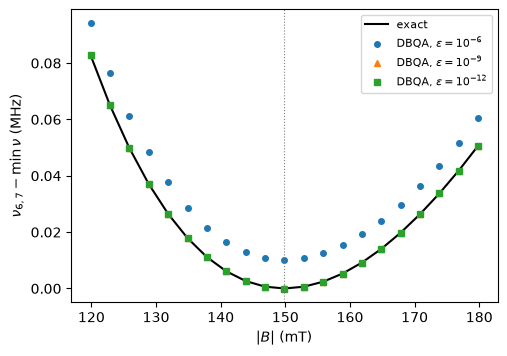

In [5]:
nu_exact = (exact[:, j] - exact[:, i]) * CM_TO_MHZ


def vertex(x, y):
    c = np.polyfit(x - b_star, y, 2)
    return b_star - c[1] / (2 * c[0]), c


_, c_exact = vertex(magnitudes, nu_exact)
b_exact, _ = vertex(magnitudes, nu_exact)
print(f"exact: parabola vertex {b_exact:.2f} mT (Newton: {b_star:.2f} mT), curvature along the line {2 * c_exact[0]:.2e} MHz/mT^2, "
      f"nu varies by {np.ptp(nu_exact):.3f} MHz over the sweep")
plt.figure(figsize=(5.5, 3.8))
plt.plot(magnitudes, nu_exact - nu_exact.min(), "k-", label="exact")
zefoz_estimates = {}
for threshold, marker in zip((1e-6, 1e-9, 1e-12), "o^s"):
    nu = np.array([np.nan if threshold not in data["stage2"][k] else data["stage2"][k][threshold]["group commutator"]["nu"][-1] for k in range(len(magnitudes))])
    ok = ~np.isnan(nu)
    if ok.sum() < 3:
        continue
    b_dbqa, _ = vertex(magnitudes[ok], nu[ok])
    zefoz_estimates[threshold] = b_dbqa
    print(f"DBQA, stage A to 1-F < {threshold:.0e}: max error of nu_ij {np.nanmax(np.abs(nu - nu_exact)):.1e} MHz, vertex {b_dbqa:.2f} mT (error {b_dbqa - b_exact:+.2f} mT)")
    plt.plot(magnitudes[ok], nu[ok] - nu_exact.min(), marker, ms=4, label=rf"DBQA, $\epsilon=10^{{{int(np.log10(threshold))}}}$")
plt.axvline(b_star, color="gray", lw=0.8, ls=":")
plt.xlabel(r"$|B|$ (mT)"); plt.ylabel(rf"$\nu_{{{i},{j}}} - \min\nu$ (MHz)")
plt.legend(fontsize=8)
plt.savefig("pdfs_figures/Er_YSO_zefoz_dbqa.pdf", bbox_inches="tight")
plt.show()

#### Compilation cost

Pauli decomposition of the embedded Hamiltonian $H(\vec B^*)$ (8 qubits, units of 5 000 cm$^{-1}$), of its field-independent part and of the field operators, and of the stage-B block (4 qubits). The CNOT counts are those of one Trotter step compiled with `add_pauli_rotation` (CNOT ladders, no cancellations), as for Models 1 and 2.

In [6]:
erhfs = ImportSLJM(pycf_matel_path("erhfs", "eryso"))
model = hyperfine_field_model(erhfs, er_yso_pycf_coeff(hyperfine=ER_YSO_SITE2_HYPERFINE_JOBBITT2021))
operators = field_operators(model)
unit = data["energy_unit"]
padded, nqubits, _ = embed_in_qubits(linear_field_hamiltonian(model["h0"], operators, sweep["field"]))
decomposition = pauli_decomposition(padded / unit)
weights = np.bincount([pauli_weight(s) for s in decomposition], minlength=nqubits + 1)
print(f"H(B*): {len(decomposition)} Pauli strings out of {4**nqubits}; by weight 0..{nqubits}: {weights}")
print(f"   CNOTs per Trotter step: first order {trotter_cnot_count(decomposition, 1)}, second order {trotter_cnot_count(decomposition, 2)}")
zero_field = pauli_decomposition(embed_in_qubits(model["h0"])[0] / unit)
field_terms = [pauli_decomposition(np.pad(v, (0, 16)) / unit) for v in operators]
print(f"H0: {len(zero_field)} strings; field operators V_x, V_y, V_z: {[len(d) for d in field_terms]} strings")
block = data["cold"][int(np.argmin(np.abs(magnitudes - b_star)))]["captured"][1e-12]["block"]
block_decomposition = pauli_decomposition((block - np.trace(block).real / 16 * np.eye(16)) / np.max(np.abs(np.linalg.eigvalsh(block - np.trace(block).real / 16 * np.eye(16)))))
print(f"stage-B block (4 qubits): {len(block_decomposition)} strings, CNOTs per first-order step {trotter_cnot_count(block_decomposition, 1)}")
with open("simulation_results/Er_LiYF4_compilation_L_9.pickle", "rb") as file:
    model2 = pickle.load(file)
print(f"for comparison, Model 2 (Er:LiYF4, 9 qubits): {model2['n_pauli']} strings, {model2['cnot_first_order']} CNOTs per first-order step; "
      f"Model 1 (Ce:YAG, 4 qubits): {model2['n_pauli_ce_yag']} strings, {model2['cnot_first_order_ce_yag']} CNOTs")
with open("simulation_results/Er_YSO_compilation_L_8.pickle", "wb") as file:
    pickle.dump(dict(n_pauli=len(decomposition), weights=weights, cnot_first_order=trotter_cnot_count(decomposition, 1),
                     cnot_second_order=trotter_cnot_count(decomposition, 2), n_pauli_h0=len(zero_field),
                     n_pauli_field=[len(d) for d in field_terms], n_pauli_block=len(block_decomposition),
                     cnot_first_order_block=trotter_cnot_count(block_decomposition, 1), zefoz_estimates=zefoz_estimates), file)

H(B*): 5978 Pauli strings out of 65536; by weight 0..8: [   1   18  107  383  820 1228 1524 1379  518]
   CNOTs per Trotter step: first order 55530, second order 111048
H0: 5718 strings; field operators V_x, V_y, V_z: [256, 256, 143] strings
stage-B block (4 qubits): 251 strings, CNOTs per first-order step 1018
for comparison, Model 2 (Er:LiYF4, 9 qubits): 93184 strings, 1073026 CNOTs per first-order step; Model 1 (Ce:YAG, 4 qubits): 71 strings, 272 CNOTs


#### Conclusions

- **Stage A** isolates the 16 hyperfine states of Z1 to $1-F<10^{-9}$ in about 105 group-commutator iterations at every field; the durations must reach about the inverse of the Z1–Z2 gap in the rescaled units.
- **Isolation sets accuracy:** the Z1 transition frequencies inherit errors of about 300, 0.3, $2\times10^{-4}$ and $3\times10^{-5}$ MHz at $1-F = 10^{-3}, 10^{-6}, 10^{-9}, 10^{-12}$.
- **Stage B** (group commutator) reaches that floor in 60 iterations; the canonical bracket stalls at a fixed point because the block's diagonal is nearly degenerate, and Pauli-Z is slow.
- **Field sweep:** warm starts need no stage-A iteration to $10^{-6}$; replaying the previous field's durations reaches $10^{-12}$ without any new step, so the schedule only needs to be found once.
- **ZEFOZ:** the turning point of $\nu_{6,7}$ is located to 0.2 mT ($10^{-6}$) and better than 0.01 mT ($10^{-9}$), although $\nu_{6,7}$ varies by only 0.083 MHz over the sweep.
- **Cost:** 5 978 Pauli strings, $5.6\times10^4$ CNOTs per first-order Trotter step: 19 times cheaper than Model 2.

`RESULTS_Model_3.md` collects these numbers.